# Head-to-Head: what does Random Forest’s complexity buy us?

We compare both **saved model outputs** on the same 9,009 test songs. The majority baseline uses training labels. We do not tune models on the test set.

The confirmed original Random Forest now reproduces every saved label and probability. The LR refit also passes that complete check. The final common permutation and complexity analysis uses scikit-learn 1.9.1, matching the forest’s embedded version. All shared inputs and other teammates’ notebooks are preserved. See `README.md` and `results/report.html` for the audit, methods and professor Q&A.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

# Works from the repository root or from this notebook's folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "common.py").exists() and (p / "clean_songs.csv").exists())
SECTION = ROOT / "work/5_head_to_head"
sys.path.insert(0, str(SECTION))
from evaluate import run, sha256, fitted_model_sha256, default_forest_path, validate_predictions, metric_rows
import importlib.util
spec = importlib.util.spec_from_file_location("project_common", ROOT / "common.py")
common = importlib.util.module_from_spec(spec)
spec.loader.exec_module(common)
RESULTS = SECTION / "results"
REBUILD_RESULTS = False  # True reruns fixed refits, five feature shuffles, and the bootstrap.
if REBUILD_RESULTS or not (RESULTS / "audit.json").exists():
    run(ROOT, RESULTS)
audit = json.loads((RESULTS / "audit.json").read_text())
for filename, checksum in audit["files_sha256"].items():
    assert sha256(ROOT / filename) == checksum, f"Changed input: {filename}. Rebuild the results."
assert fitted_model_sha256(default_forest_path()) == audit["fitted_rf_model"]["sha256"]
print("All shared inputs and the fitted-model hash match the saved evaluation.")
print("Source commit:", audit["repository_commit"])
print("Evaluation versions:", audit["environment"])

All shared inputs and the fitted-model hash match the saved evaluation.
Source commit: 8c272308324ea2f292c195b4eb308bbf8cfa99dd
Evaluation versions: {'python': '3.12.5', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'platform': 'macOS-15.5-arm64-arm-64bit'}


## 1. What is ready?

The integration branch starts from main at `b90ad09`. Data Prep has 11 cells, Data Explorer 15, Logistic Regression 15, and Random Forest 16. The completed forest notebook matches the supplied copy. The team deck has 21 slides. Shared data, recipes and prediction files retain the original snapshot hashes. The verified original forest, common permutation comparison, measured complexity and presentation are included in this section. The legacy 70.5% forest result uses another workflow and is excluded.

In [2]:
songs = pd.read_csv(ROOT / "clean_songs.csv")
train = songs[songs.split == "train"].copy()
test = songs[songs.split == "test"].copy().reset_index(drop=True)
print(f"{len(songs):,} total / {len(train):,} train / {len(test):,} test")
display(pd.crosstab(songs.broad_genre, songs.split))
print("Predictors:", common.FEATURES)
print("Missing predictor values:", int(songs[common.FEATURES].isna().sum().sum()))

45,046 total / 36,037 train / 9,009 test
Predictors: ['duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
Missing predictor values: 0


split,test,train
broad_genre,,
electronic,2730,10920
hiphop/rnb,381,1525
latin,1474,5898
pop,2041,8165
rock,2383,9529


## 2. Verify alignment before calculating metrics

Rows can be in different orders. We align by unique track ID and validate against the shared test labels and metadata. Named probability columns define the class order. Invalid partial probabilities fail loudly. The majority baseline uses **training** labels only.

In [3]:
aligned, probabilities = {}, {}
for model in ["logistic_regression", "random_forest"]:
    aligned[model], probabilities[model], checks = validate_predictions(
        pd.read_csv(ROOT / f"predictions/{model}.csv"), test, common.GENRES)
    print(model, checks)
majority = train.broad_genre.value_counts().idxmax()
baseline_probability = np.zeros((len(test), len(common.GENRES)))
baseline_probability[:, common.GENRES.index(majority)] = 1
print("Baseline chosen from training:", majority)

logistic_regression {'rows': 9009, 'original_order_matches': True, 'alignment': 'track_id', 'probability_columns': ['proba_electronic', 'proba_hiphop/rnb', 'proba_latin', 'proba_pop', 'proba_rock']}
random_forest {'rows': 9009, 'original_order_matches': True, 'alignment': 'track_id', 'probability_columns': ['proba_electronic', 'proba_hiphop/rnb', 'proba_latin', 'proba_pop', 'proba_rock']}
Baseline chosen from training: electronic


## 3. Held-out performance against the baseline

Accuracy weights every song equally. Macro precision, recall and F1 give every genre equal weight. Macro F1 averages the five genre F1 values. ROC-AUC uses macro one-vs-rest probability rankings, so it answers a different question from accuracy.

In [4]:
overall, per_genre = [], []
y = test.broad_genre.to_numpy()
for model in ["baseline", "logistic_regression", "random_forest"]:
    predicted = np.repeat(majority, len(test)) if model == "baseline" else aligned[model].predicted.to_numpy()
    proba = baseline_probability if model == "baseline" else probabilities[model]
    row, rows = metric_rows(y, predicted, proba, common.GENRES, model)
    overall.append(row); per_genre.extend(rows)
overall = pd.DataFrame(overall)
per_genre = pd.DataFrame(per_genre)
saved = pd.read_csv(RESULTS / "tables/overall_metrics.csv")
np.testing.assert_allclose(overall.select_dtypes("number"), saved.select_dtypes("number"), atol=1e-12)
display(overall.round(6))
print("Independently recomputed metrics agree with the saved tables.")

Independently recomputed metrics agree with the saved tables.


,model,accuracy,macro_precision,macro_recall,macro_f1,roc_auc_ovr_macro,correct,test_songs
0,baseline,0.303030,0.060606,0.200000,0.093023,0.500000,2730,9009
1,logistic_regression,0.569542,0.531620,0.482739,0.488566,0.816055,5131,9009
2,random_forest,0.640249,0.631606,0.546954,0.555864,0.869853,5768,9009


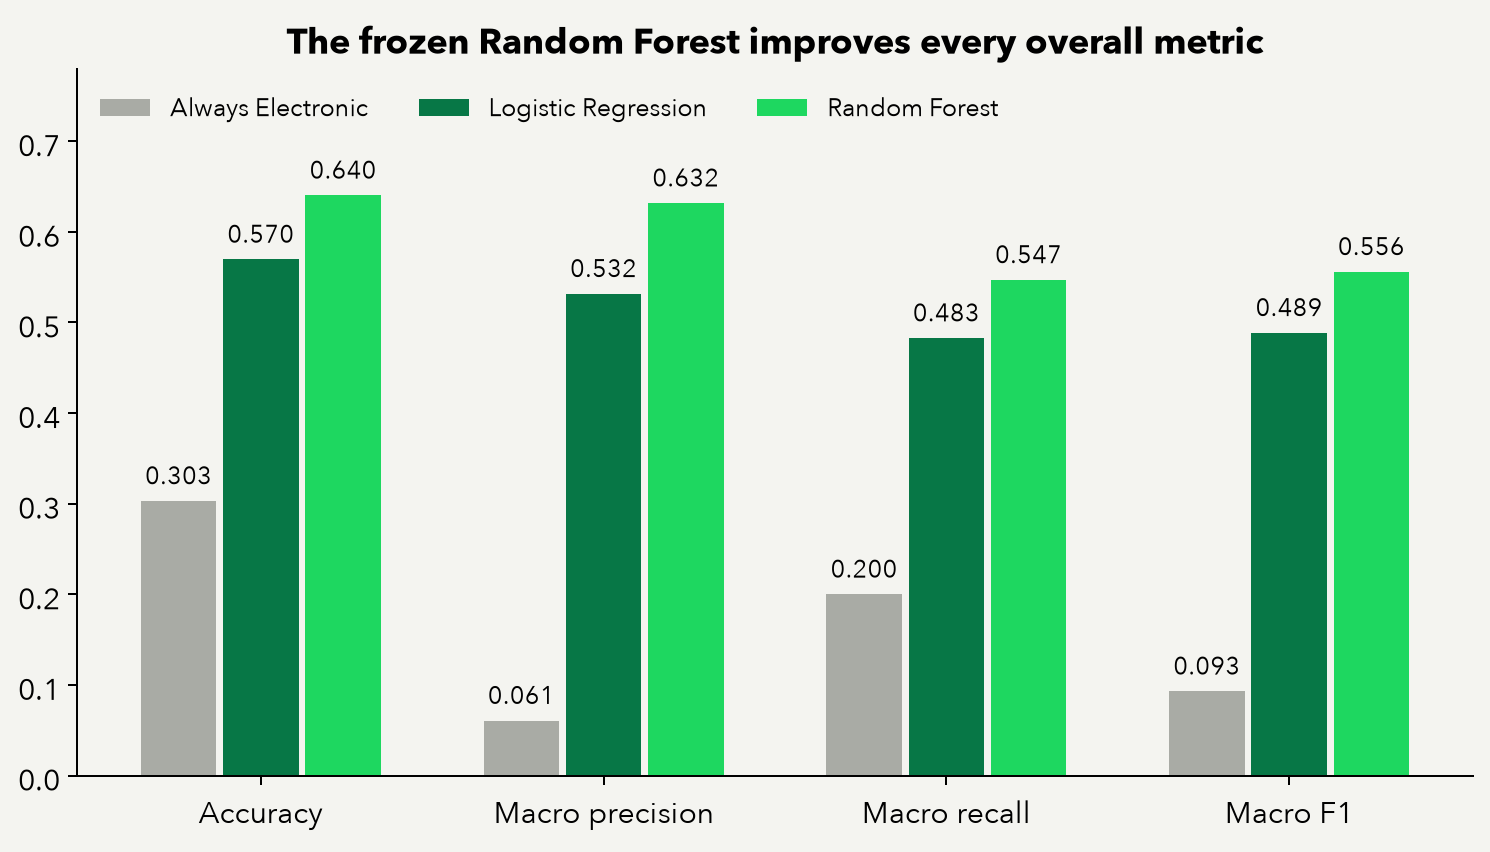

In [5]:
display(Image(filename=str(RESULTS / "charts/overall_metrics.png")))

## 4. Where does the forest gain?

A descriptive tie means an absolute F1 difference of at most 0.01. This is a reporting convention, not a statistical equivalence test. Random Forest improves every genre’s F1. Latin has the largest gain. Hip-hop/R&B remains weak: the forest finds 49/381 test tracks, compared with LR’s 38/381.

,model,genre,precision,recall,f1,support
5,logistic_regression,electronic,0.6642,0.6832,0.6735,2730
6,logistic_regression,hiphop/rnb,0.4043,0.0997,0.1600,381
7,logistic_regression,latin,0.5685,0.5516,0.5599,1474
8,logistic_regression,pop,0.4321,0.4586,0.4450,2041
9,logistic_regression,rock,0.5890,0.6206,0.6044,2383
10,random_forest,electronic,0.7070,0.7821,0.7426,2730
11,random_forest,hiphop/rnb,0.6282,0.1286,0.2135,381
12,random_forest,latin,0.6425,0.6438,0.6432,1474
13,random_forest,pop,0.5012,0.5194,0.5101,2041
14,random_forest,rock,0.6792,0.6609,0.6699,2383


,genre,delta_precision,delta_recall,delta_f1,f1_comparison,descriptive_tie_margin_f1
0,electronic,0.0428,0.0989,0.0691,Random Forest wins,0.01
1,hiphop/rnb,0.2239,0.0289,0.0535,Random Forest wins,0.01
2,latin,0.0740,0.0923,0.0833,Random Forest wins,0.01
3,pop,0.0690,0.0608,0.0651,Random Forest wins,0.01
4,rock,0.0902,0.0403,0.0655,Random Forest wins,0.01


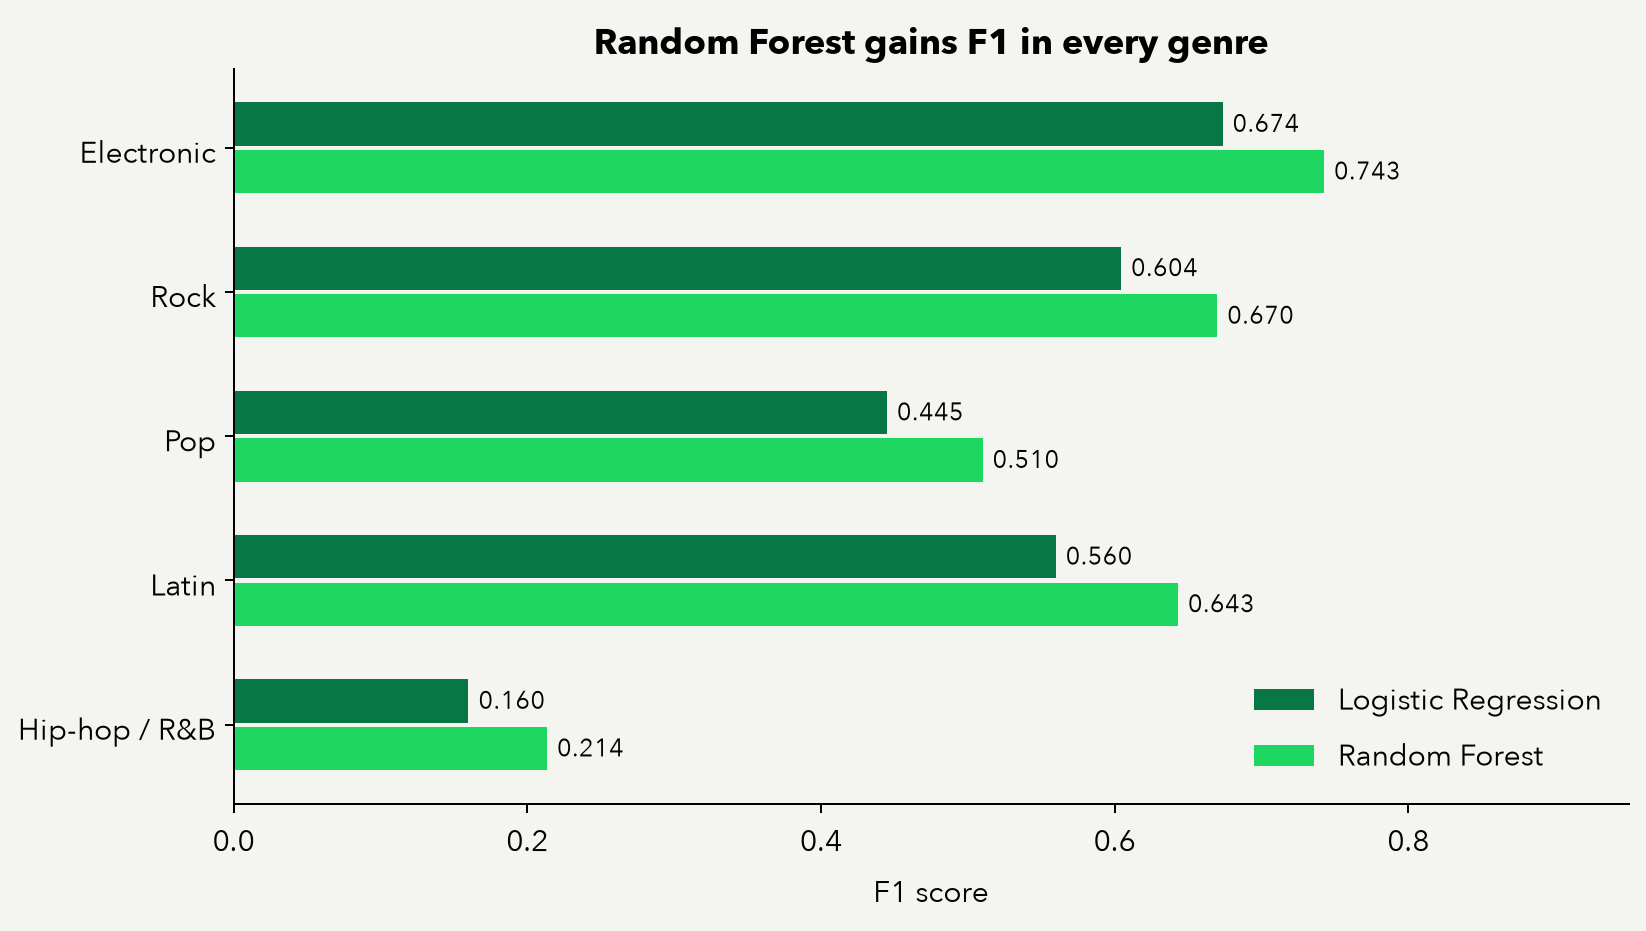

In [6]:
display(per_genre[per_genre.model != "baseline"].round(4))
display(pd.read_csv(RESULTS / "tables/genre_deltas.csv").round(4))
display(Image(filename=str(RESULTS / "charts/genre_f1.png")))

## 5. Songs one model gets right while the other gets wrong

The forest has 1,221 unique successes, while LR has 584. The net is 637 additional correct tracks. A different predicted label does not always mean one model is right: both can give different wrong labels. Representative examples use the middle true-class probability difference within each genre/outcome group, with track ID as a tie-breaker.

In [7]:
paired = pd.read_csv(RESULTS / "tables/paired_tracks.csv")
assert len(paired) == len(test)
assert paired.track_id.tolist() == test.track_id.tolist()
display(pd.read_csv(RESULTS / "tables/paired_outcomes.csv"))
display(pd.read_csv(RESULTS / "tables/paired_outcomes_by_genre.csv"))
print("Different predicted labels:", int(paired.models_disagree.sum()))
examples = pd.read_csv(RESULTS / "tables/representative_tracks.csv")
display(examples[["artists", "track_name", "broad_genre", "lr_predicted", "rf_predicted", "outcome"]])

Different predicted labels: 2394


,outcome,songs
0,both_correct,4547
1,both_wrong,2657
2,rf_only_correct,1221
3,lr_only_correct,584


,genre,both_correct,both_wrong,lr_only_correct,rf_only_correct,net_extra_correct_rf
0,electronic,1771,501,94,364,270
1,hiphop/rnb,29,323,9,20,11
2,latin,742,454,71,207,136
3,pop,723,768,213,337,124
4,rock,1282,611,197,293,96


,artists,track_name,broad_genre,lr_predicted,rf_predicted,outcome
0,Shade k,Eskimos,electronic,pop,electronic,rf_only_correct
1,Seekae,John Duncan,electronic,electronic,rock,lr_only_correct
2,ZZ Top,Sharp Dressed Man - 2008 Remaster,rock,electronic,rock,rf_only_correct
3,BOØWY,CELLULOID DOLL,rock,rock,pop,lr_only_correct
4,Duran Duran,"Careless Memories - Live at Oakland Coliseum, ...",pop,rock,pop,rf_only_correct
5,my little airport,你說之後會找我 - LIVE,pop,pop,rock,lr_only_correct
6,Desejo De Menina,Mil Perdões,latin,rock,latin,rf_only_correct
7,Eduardo Costa,Esta Noite Foi Maravilhosa,latin,latin,pop,lr_only_correct
8,Shaker,Next,hiphop/rnb,latin,hiphop/rnb,rf_only_correct
9,Coolio;L.V.,That's How It Is - Skit,hiphop/rnb,hiphop/rnb,rock,lr_only_correct


## 6. Uncertainty and artist grouping

The paired cluster bootstrap samples **full artist credit groups**, giving both models exactly the same sampled songs. It uses 2,000 resamples, seed 4241. Its interval describes sampling variation on this split with fixed fitted models.

Full artist strings do not cross train/test, but individual collaborators can. The semicolon-token audit finds 2,401 shared names, affecting 5,072 test tracks. It uses exact normalized names, not artist identity resolution. Do not claim every individual test artist is unseen.

In [8]:
display(pd.read_csv(RESULTS / "tables/paired_bootstrap.csv").round(6))
print("Exact artist-credit overlap:", audit["exact_artist_credit_overlap"])
print("Shared individual artist tokens:", audit["shared_individual_artist_tokens"])
print("Affected test tracks:", audit["test_tracks_with_individual_artist_overlap"])
display(pd.read_csv(RESULTS / "tables/artist_overlap_subgroups.csv").round(4))

Exact artist-credit overlap: 0
Shared individual artist tokens: 2401
Affected test tracks: 5072


,metric,low_95,high_95,resamples,unit,seed,observed_difference_rf_minus_lr
0,accuracy,0.052405,0.088103,2000,full artist credit string,4241,0.070707
1,macro_f1,0.049956,0.084145,2000,full artist credit string,4241,0.067298


,model,accuracy,macro_precision,macro_recall,macro_f1,roc_auc_ovr_macro,correct,test_songs,individual_artist_overlap
0,logistic_regression,0.5522,0.4966,0.4578,0.4395,NaN,2174,3937,False
1,random_forest,0.6063,0.6097,0.5204,0.4987,NaN,2387,3937,False
2,logistic_regression,0.5830,0.5254,0.4844,0.4894,NaN,2957,5072,True
3,random_forest,0.6666,0.6335,0.5562,0.5695,NaN,3381,5072,True


## 7. Common feature importance and measured complexity

Both models now answer the same question: how much does macro F1 (or accuracy) decrease after shuffling one feature on the same test songs? Each uses the same five shuffles, seed 4241. The original forest and the fixed LR refit must first reproduce all saved labels and probabilities, with matching feature/class order.

RF’s largest mean macro-F1 drops are Acousticness (0.1282), Danceability (0.1055) and Instrumentalness (0.1016). LR’s are Danceability (0.1024), Acousticness (0.0786) and Valence (0.0562). These scores describe predictive reliance. Correlated features can share importance, and shuffling can create unusual combinations. This is interpretation of fixed models, never tuning or a causal analysis.

Unresolved model dependencies: []


,model,source,label_agreement,probability_max_abs_difference,model_test_accuracy,differing_labels,matches_saved_outputs
0,logistic_regression,fixed_recipe_refit_on_train,1.0,1.171285e-13,0.569542,0,True
1,random_forest,confirmed_original_fitted_model,1.0,2.220446e-16,0.640249,0,True


,model,metric,feature,mean_score_drop,sd_score_drop,repeats
36,random_forest,macro_f1,acousticness,0.12824,0.00171,5
30,random_forest,macro_f1,danceability,0.10552,0.00190,5
2,logistic_regression,macro_f1,danceability,0.10241,0.00287,5
37,random_forest,macro_f1,instrumentalness,0.10158,0.00352,5
8,logistic_regression,macro_f1,acousticness,0.07863,0.00286,5
39,random_forest,macro_f1,valence,0.06651,0.00220,5
11,logistic_regression,macro_f1,valence,0.05625,0.00386,5
9,logistic_regression,macro_f1,instrumentalness,0.05112,0.00064,5
35,random_forest,macro_f1,speechiness,0.03764,0.00234,5
3,logistic_regression,macro_f1,energy,0.03734,0.00432,5


,model,source,fit_seconds,load_seconds,prediction_batch_seconds_median,prediction_repeats,workers,serialized_bytes,coefficients,intercepts,trees,tree_nodes,median_depth,max_depth
0,logistic_regression,fixed_recipe_refit_on_train,0.114691,NaN,0.002088,5,1,2283,70.0,5.0,NaN,NaN,NaN,NaN
1,random_forest,confirmed_original_fitted_model,NaN,0.115291,0.256173,5,1,185700394,NaN,NaN,300.0,1784632.0,27.0,36.0


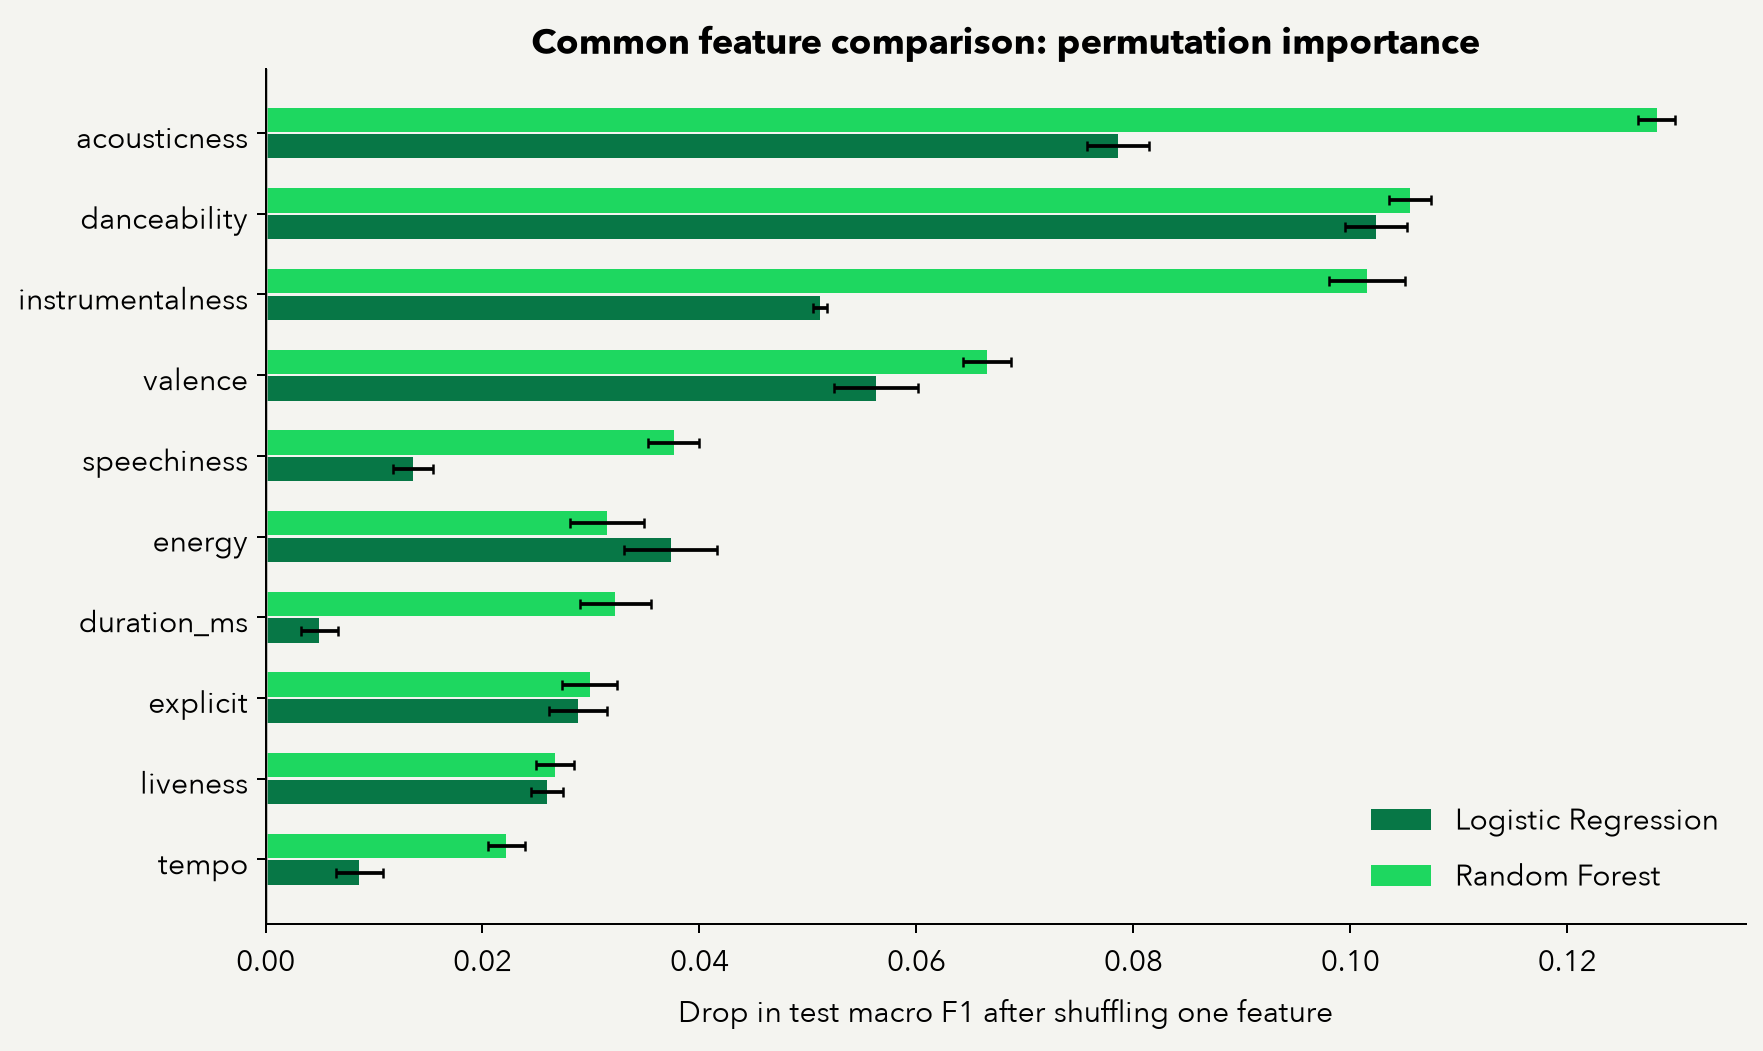

,feature,lr_macro_f1_drop,rf_macro_f1_drop,rf_minus_lr_drop
0,acousticness,0.07863,0.12824,0.04961
1,danceability,0.10241,0.10552,0.00311
2,instrumentalness,0.05112,0.10158,0.05045
3,valence,0.05625,0.06651,0.01027
4,speechiness,0.01361,0.03764,0.02403
5,duration_ms,0.00495,0.03226,0.02731
6,energy,0.03734,0.03147,-0.00587
7,explicit,0.02882,0.02991,0.00108
8,liveness,0.02597,0.02666,0.00069
9,tempo,0.00863,0.02222,0.01358


In [9]:
display(pd.read_csv(RESULTS / "tables/model_verification.csv"))
importance = pd.read_csv(RESULTS / "tables/permutation_importance.csv")
display(importance[importance.metric == "macro_f1"].sort_values("mean_score_drop", ascending=False).round(5))
print("Unresolved model dependencies:", audit["unresolved_dependencies"])
display(pd.read_csv(RESULTS / "tables/complexity.csv"))
display(Image(filename=str(RESULTS / "charts/permutation_importance.png")))
display(pd.read_csv(RESULTS / "tables/common_permutation_comparison.csv").round(5))

### Supporting evidence from the forest notebook

The teammate’s recorded Gini ranking starts with Acousticness, Danceability and Instrumentalness. Those values agree with the confirmed original forest to the notebook’s six-decimal precision. They provide context; the primary head-to-head comparison uses the same test-permutation definition for both models.

The supplied depth/weighting code and recorded CV outputs are inspected as supporting evidence, without rerunning the experiments. They use training folds and do not replace the frozen unweighted forest’s test results.

In [10]:
from audit_teammate_inputs import audit_inputs
teammate_audit = audit_inputs()
display(pd.read_csv(RESULTS / "tables/feature_rankings_different_measures.csv")[["rank", "lr_feature", "rf_feature"]].head(5))
display(pd.read_csv(RESULTS / "tables/teammate_rf_gini_importance.csv")[["rank", "feature", "gini_share"]])
display(pd.read_csv(RESULTS / "tables/teammate_rf_depth_cv.csv"))
display(pd.read_csv(RESULTS / "tables/teammate_rf_weight_cv.csv"))
print("Confirmed original forest included. Shared inputs remain unchanged.")

New CSVs verified. RF notebook evidence extracted without execution.
         feature  gini_share  rank                                     method                                                     provenance
    acousticness    0.168088     1 training-fitted RF Gini impurity reduction teammate notebook recorded output, 6 decimal places; not rerun
    danceability    0.144190     2 training-fitted RF Gini impurity reduction teammate notebook recorded output, 6 decimal places; not rerun
instrumentalness    0.141101     3 training-fitted RF Gini impurity reduction teammate notebook recorded output, 6 decimal places; not rerun
         valence    0.088118     4 training-fitted RF Gini impurity reduction teammate notebook recorded output, 6 decimal places; not rerun
     duration_ms    0.084514     5 training-fitted RF Gini impurity reduction teammate notebook recorded output, 6 decimal places; not rerun
Confirmed original forest included. Shared inputs remain unchanged.


,rank,lr_feature,rf_feature
0,1,danceability,acousticness
1,2,acousticness,danceability
2,3,valence,instrumentalness
3,4,instrumentalness,valence
4,5,energy,duration_ms


,rank,feature,gini_share
0,1,acousticness,0.168088
1,2,danceability,0.144190
2,3,instrumentalness,0.141101
3,4,valence,0.088118
4,5,duration_ms,0.084514
5,6,energy,0.076050
6,7,speechiness,0.067257
7,8,liveness,0.065313
8,9,tempo,0.064557
9,10,loudness,0.055921


,max_depth,mean_fold_train_accuracy,mean_fold_validation_accuracy,provenance
0,5.0,0.591,0.579,"teammate notebook recorded output, 3 decimal p..."
1,10.0,0.691,0.623,"teammate notebook recorded output, 3 decimal p..."
2,15.0,0.814,0.643,"teammate notebook recorded output, 3 decimal p..."
3,20.0,0.866,0.646,"teammate notebook recorded output, 3 decimal p..."
4,NaN,0.873,0.647,"teammate notebook recorded output, 3 decimal p..."


,class_weight,mean_validation_accuracy,mean_validation_macro_f1,provenance
0,NaN,0.647,0.553,"teammate notebook recorded output, 3 decimal p..."
1,balanced,0.629,0.573,"teammate notebook recorded output, 3 decimal p..."
2,balanced_subsample,0.638,0.579,"teammate notebook recorded output, 3 decimal p..."


## 8. Verdict and presentation

For accuracy on this shared test set, Random Forest earns its added complexity: +7.07 percentage points, +0.0673 macro F1 and F1 gains in every genre. It has 300 trees and 1,784,632 nodes, versus LR’s 70 coefficients plus 5 intercepts. Serialized sizes are about 185.7 MB versus 2.3 KB. Median local batch-prediction times were about 0.256 versus 0.0021 seconds for the same 9,009 songs, using one worker. These are indicative local timings, not production benchmarks. Original RF training wall time was not recorded.

Use slides 1–2 for about two minutes. Hidden backups cover paired errors and common feature importance. The report and notes include professor Q&A.

Keep the artist limitation visible: full credit groups are separate, while collaborators can cross the split. Historical genre-selection decisions cannot be fully audited. The legacy score and class-weighting experiment remain outside this frozen comparison.